# Multiple Comparisons

Companion notebook for [notes/hypothesis_testing_and_confidence_intervals/multiple_comparisons.md](../../notes/hypothesis_testing_and_confidence_intervals/multiple_comparisons.md).

When many hypotheses are tested, false positives accumulate. Procedures such as Bonferroni and Holm control the family-wise error rate (FWER); Benjamini-Hochberg controls the false discovery rate (FDR). We quantify the problem and compare the corrections by simulation.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)

## 1. How fast false positives accumulate

For $m$ independent true nulls tested at $\alpha=0.05$, $P(\text{at least one rejection})=1-(1-\alpha)^m$.

m=  1: P(>=1 false positive) = 0.050
m=  5: P(>=1 false positive) = 0.226
m= 10: P(>=1 false positive) = 0.401
m= 20: P(>=1 false positive) = 0.642
m= 50: P(>=1 false positive) = 0.923
m=100: P(>=1 false positive) = 0.994


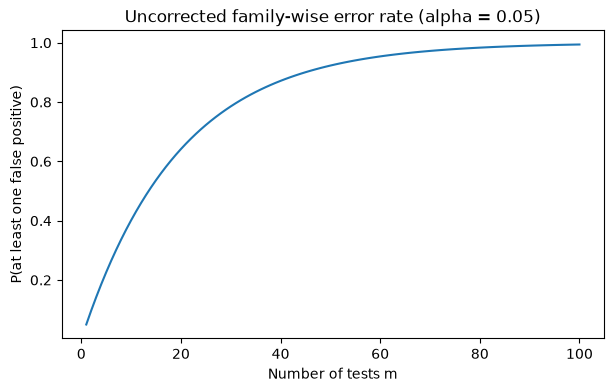

In [2]:
ms = np.arange(1, 101)
fwer = 1 - 0.95 ** ms
for m in (1, 5, 10, 20, 50, 100):
    print(f"m={m:3d}: P(>=1 false positive) = {1 - 0.95 ** m:.3f}")

plt.figure(figsize=(7, 4))
plt.plot(ms, fwer)
plt.xlabel("Number of tests m")
plt.ylabel("P(at least one false positive)")
plt.title("Uncorrected family-wise error rate (alpha = 0.05)")
plt.show()

## 2. Implementing the procedures

All three work on sorted p-values. Holm steps down and stops at the first non-rejection; BH steps up, rejecting everything up to the largest $i$ with $p_{(i)}\le\frac{i}{m}\alpha$.

In [3]:
def bonferroni(p, alpha=0.05):
    return p <= alpha / len(p)

def holm(p, alpha=0.05):
    m = len(p)
    order = np.argsort(p)
    reject = np.zeros(m, dtype=bool)
    for rank, idx in enumerate(order):
        if p[idx] <= alpha / (m - rank):
            reject[idx] = True
        else:
            break
    return reject

def benjamini_hochberg(p, alpha=0.05):
    m = len(p)
    order = np.argsort(p)
    thresholds = alpha * np.arange(1, m + 1) / m
    passed = np.where(p[order] <= thresholds)[0]
    reject = np.zeros(m, dtype=bool)
    if passed.size:
        reject[order[: passed.max() + 1]] = True
    return reject

p = np.array([0.001, 0.008, 0.039, 0.041, 0.042, 0.06])
print("p-values:   ", p)
print("Bonferroni: ", bonferroni(p).sum(), "rejections")
print("Holm:       ", holm(p).sum(), "rejections")
print("BH:         ", benjamini_hochberg(p).sum(), "rejections")

p-values:    [0.001 0.008 0.039 0.041 0.042 0.06 ]
Bonferroni:  2 rejections
Holm:        2 rejections
BH:          2 rejections


For the note's six p-values, all three reject the first two hypotheses. The next example shows where they differ.

In [4]:
p2 = np.array([0.003, 0.012, 0.018, 0.040, 0.30])
print("p-values:   ", p2)
print("Bonferroni: ", bonferroni(p2).sum(), "rejections")
print("Holm:       ", holm(p2).sum(), "rejections")
print("BH:         ", benjamini_hochberg(p2).sum(), "rejections")

p-values:    [0.003 0.012 0.018 0.04  0.3  ]
Bonferroni:  1 rejections
Holm:        2 rejections
BH:          4 rejections


## 3. Simulation: FWER versus FDR

We test 1,000 hypotheses per experiment, 100 of which are truly non-null (mean shift 3). We repeat 200 times and record, for each method, the average number of discoveries, the probability of at least one false discovery, and the average false discovery proportion.

In [5]:
m, m1, reps = 1000, 100, 200
res = {name: {"disc": [], "anyfp": [], "fdp": []} for name in ["None", "Bonferroni", "Holm", "BH"]}

for _ in range(reps):
    z = rng.normal(0, 1, m)
    z[:m1] += 3.0
    p = 2 * stats.norm.sf(np.abs(z))
    truth_null = np.arange(m) >= m1
    decisions = {
        "None": p <= 0.05,
        "Bonferroni": bonferroni(p),
        "Holm": holm(p),
        "BH": benjamini_hochberg(p),
    }
    for name, rej in decisions.items():
        fp = np.sum(rej & truth_null)
        res[name]["disc"].append(rej.sum())
        res[name]["anyfp"].append(fp > 0)
        res[name]["fdp"].append(fp / max(rej.sum(), 1))

print(f"{'Method':12s}{'discoveries':>12s}{'P(any FP)':>12s}{'mean FDP':>10s}")
for name, r in res.items():
    print(f"{name:12s}{np.mean(r['disc']):12.1f}{np.mean(r['anyfp']):12.3f}{np.mean(r['fdp']):10.3f}")

Method       discoveries   P(any FP)  mean FDP
None               130.4       1.000     0.348
Bonferroni          14.4       0.070     0.004
Holm                14.5       0.070     0.004
BH                  51.4       0.905     0.048


Without correction, roughly a third of the discoveries are false and some false positive is essentially certain. Bonferroni and Holm keep the chance of any false positive near 5% but find fewer true effects. BH controls the average false discovery proportion at about 5% while finding many more true effects than the FWER methods.

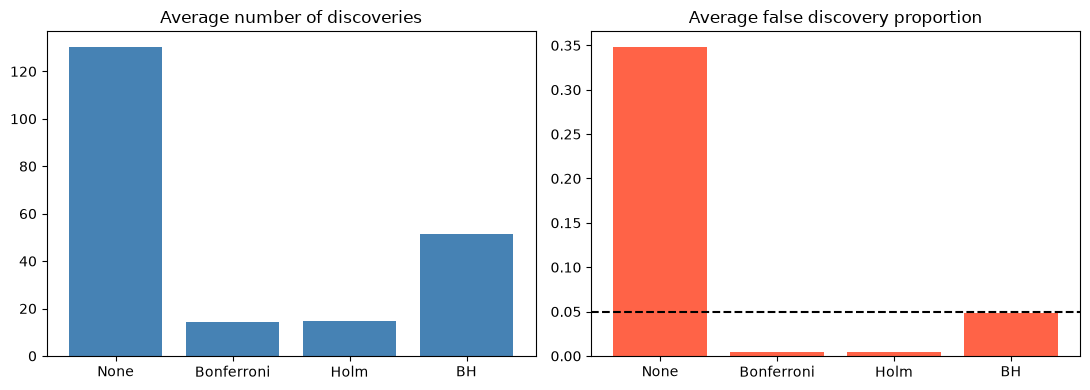

In [6]:
names = list(res)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(names, [np.mean(res[n]["disc"]) for n in names], color="steelblue")
axes[0].set_title("Average number of discoveries")
axes[1].bar(names, [np.mean(res[n]["fdp"]) for n in names], color="tomato")
axes[1].axhline(0.05, color="black", linestyle="--")
axes[1].set_title("Average false discovery proportion")
plt.tight_layout()
plt.show()